# GARCH(1,1) scenario generator

## Model

- Zero-mean GARCH(1,1) with Student-t innovations, quasi-maximum-likelihood, implemented by hand following the conventions of the `arch` library (no new dependency): `models/sigma_garch.py`.
- Same 3-factor PCA and VAR(1) mean as the var1 model. The VAR residuals are `eps_t = sigma_t * z_t` with `z_t` unit-variance Student-t (df per factor): `models/var1_garch.py`.
- Per factor: `sigma_t^2 = omega + alpha * eps_{t-1}^2 + beta * sigma_{t-1}^2`, fitted independently.
- Each simulation starts from the current conditional variance at the forecast origin, not from the long-run level.

**Limitation.** The three factors have separate GARCH processes, but their volatility regimes are correlated (squared VAR residuals correlate 0.48 between PC1 and PC2, 0.32 between PC1 and PC3). A shock to one factor does not raise the volatility of the others, so a shared volatility regime is under-represented. Accepted as a limitation of this model.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from scenario_lab.data import load_curve
from scenario_lab.models import var1 as m, var1_garch as gm
from scenario_lab.models.sigma_garch import Garch11
from scenario_lab import validation as v
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"

levels = load_curve("AAA")
changes = levels.diff().dropna()
realised = v.realised_changes(levels)
FIT_END = v.FIT_END
mats = list(levels.columns)
print("fit end:", FIT_END, "| daily changes:", changes.shape)

fit end: 2018-12-31 | daily changes: (5677, 6)


## 1. GARCH layer: parameters and diagnostics (full sample)

Fitted parameters per factor, the conditional volatility path against var1's constant sigma, and residual checks: a QQ plot of `z = eps / sigma_t` against the fitted t, and the autocorrelation of squares before and after standardising (Ljung-Box at lag 10).

In [2]:
pg = gm.fit(changes)
pb = m.fit(changes)                                   # constant-volatility baseline

tab = pd.DataFrame([g.params._asdict() for g in pg.garch], index=["PC1", "PC2", "PC3"])
tab["alpha+beta"] = tab.alpha + tab.beta
tab["long-run std"] = np.sqrt(tab.omega / (1 - tab["alpha+beta"]))
tab["sigma now"] = np.sqrt([g.sigma2_last for g in pg.garch])
tab["var1 constant sigma"] = pb.sigma
print(tab.round(4))

     omega   alpha    beta      nu  alpha+beta  long-run std  sigma now  \
PC1    0.0  0.0488  0.9446  9.0853      0.9934        0.0864     0.0715   
PC2    0.0  0.0895  0.9066  7.0671      0.9960        0.0516     0.0352   
PC3    0.0  0.0982  0.8946  4.3518      0.9927        0.0242     0.0117   

     var1 constant sigma  
PC1               0.0872  
PC2               0.0377  
PC3               0.0189  


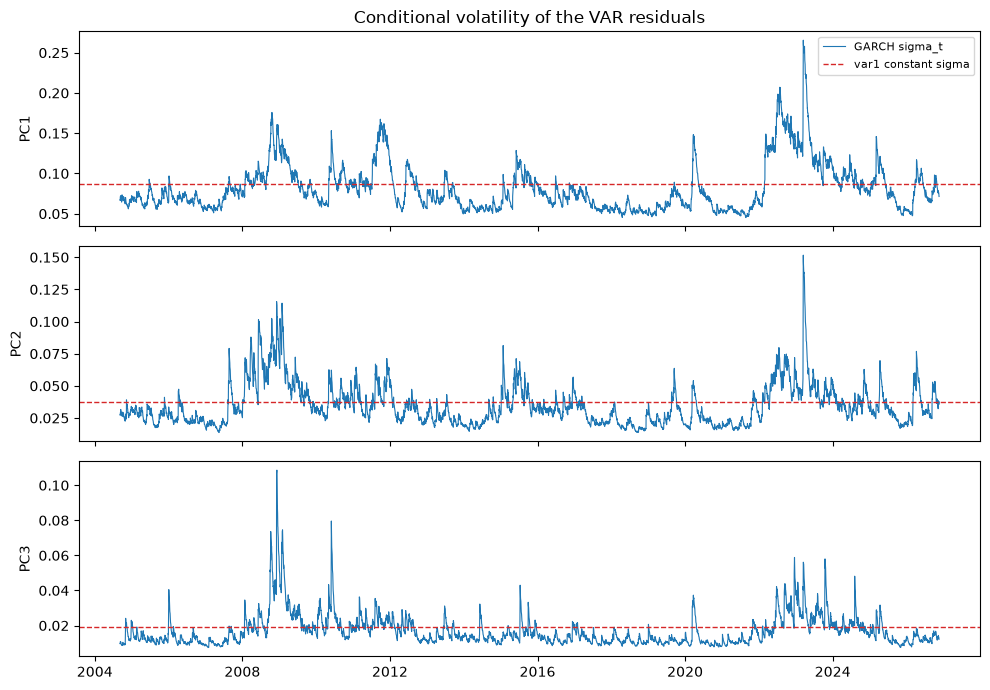

In [3]:
scores = changes.values @ pg.V
resid = scores[1:] - scores[:-1] @ pg.Phi.T          # VAR residuals (T-1, 3)
dates = changes.index[1:]
sig = np.column_stack([
    np.sqrt(Garch11.variance(resid[:, j], *pg.garch[j].params[:3], Garch11.backcast(resid[:, j]))[:-1])
    for j in range(3)])                              # sigma_t per factor, original scale
z = resid / sig

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(dates, sig[:, j], lw=0.8, label="GARCH sigma_t")
    ax.axhline(pb.sigma[j], color="C3", ls="--", lw=1, label="var1 constant sigma")
    ax.set_ylabel(f"PC{j+1}")
axes[0].legend(fontsize=8); axes[0].set_title("Conditional volatility of the VAR residuals")
plt.tight_layout(); plt.show()

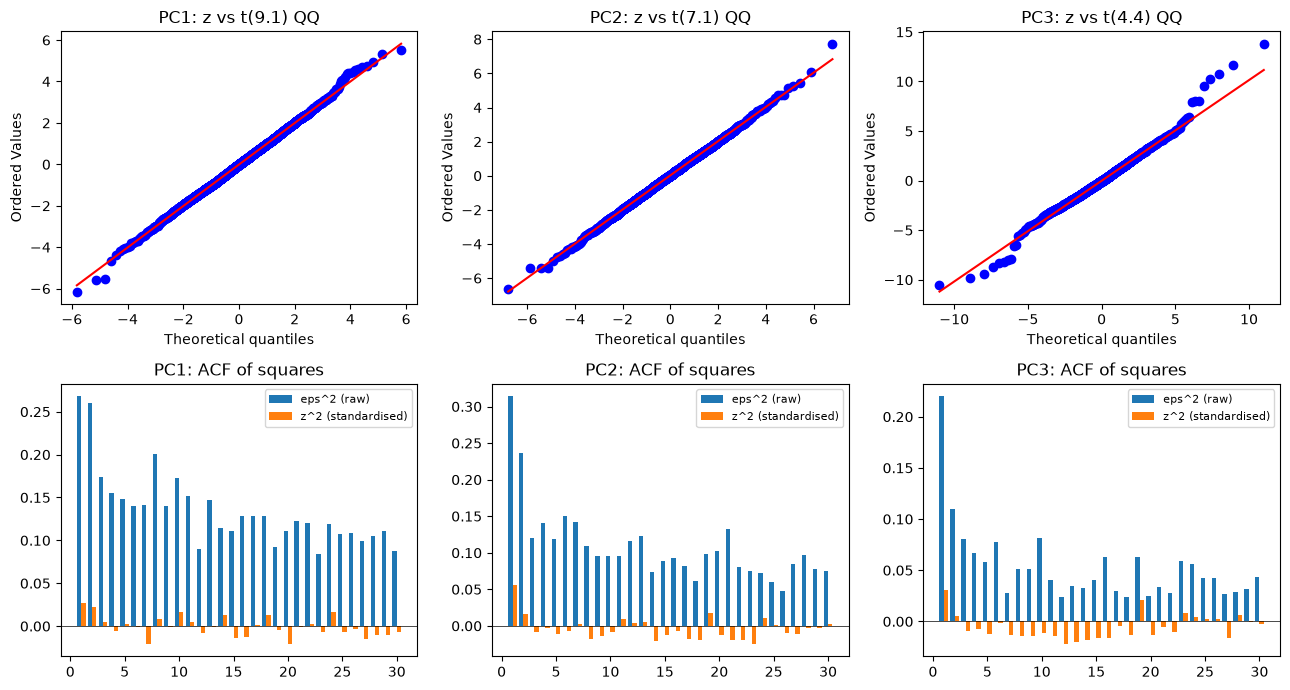

Ljung-Box p-value on squares, lag 10 (small = volatility clustering left)
     raw eps^2  standardised z^2
PC1        0.0            0.3037
PC2        0.0            0.0066
PC3        0.0            0.3524


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
lags = np.arange(1, 31)
acf = lambda s: np.array([np.corrcoef(s[:-k], s[k:])[0, 1] for k in lags])
for j in range(3):
    nu = pg.garch[j].params.nu
    stats.probplot(z[:, j] * np.sqrt(nu / (nu - 2)), dist=stats.t, sparams=(nu,), plot=axes[0, j])
    axes[0, j].set_title(f"PC{j+1}: z vs t({nu:.1f}) QQ")
    ax = axes[1, j]
    ax.bar(lags - 0.2, acf(resid[:, j] ** 2), 0.4, label="eps^2 (raw)")
    ax.bar(lags + 0.2, acf(z[:, j] ** 2), 0.4, label="z^2 (standardised)")
    ax.axhline(0, color="k", lw=0.5); ax.set_title(f"PC{j+1}: ACF of squares"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

lb = pd.DataFrame({"raw eps^2": [acorr_ljungbox(resid[:, j] ** 2, lags=[10])["lb_pvalue"].iloc[0] for j in range(3)],
                   "standardised z^2": [acorr_ljungbox(z[:, j] ** 2, lags=[10])["lb_pvalue"].iloc[0] for j in range(3)]},
                  index=["PC1", "PC2", "PC3"])
print("Ljung-Box p-value on squares, lag 10 (small = volatility clustering left)")
print(lb.round(4))

## 2. Simulation from today's curve

250-day simulations from the last curve with both models. Left: daily std of the simulated changes by simulation day (GARCH starts from the current volatility and reverts towards its long-run level). Right: std of the 250-day change by maturity.

garch (25000, 251, 6) finite: True


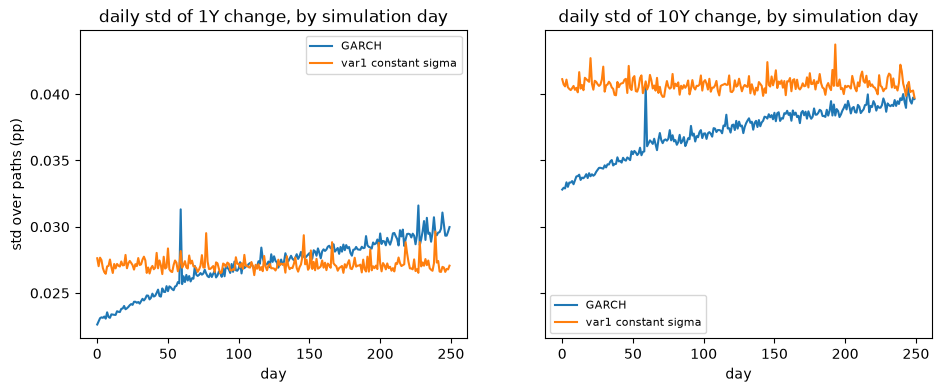

std of the 250-day change (pp)
     GARCH   var1  realised 250d (all)
1Y   0.467  0.459                1.056
2Y   0.616  0.623                0.935
5Y   0.613  0.653                0.763
10Y  0.607  0.658                0.711
20Y  0.664  0.707                0.707
30Y  0.745  0.775                0.696


In [5]:
y0 = levels.iloc[-1].values
cg = gm.simulate(pg, y0, seed=0)
cb = m.simulate(pb, y0, seed=0)
print("garch", cg.shape, "finite:", np.isfinite(cg).all())

dstd_g = np.diff(cg, axis=1).std(axis=0)             # (250, 6) daily std over paths, by day
dstd_b = np.diff(cb, axis=1).std(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, k in zip(axes, [0, 3]):
    ax.plot(dstd_g[:, k], label="GARCH"); ax.plot(dstd_b[:, k], label="var1 constant sigma")
    ax.set_title(f"daily std of {mats[k]} change, by simulation day"); ax.set_xlabel("day"); ax.legend(fontsize=8)
axes[0].set_ylabel("std over paths (pp)")
plt.show()

out = pd.DataFrame({"GARCH": (cg[:, -1] - y0).std(0), "var1": (cb[:, -1] - y0).std(0),
                    "realised 250d (all)": realised.std().values}, index=mats)
print("std of the 250-day change (pp)")
print(out.round(3))

## 3. Fan charts and day-250 quantiles (production fit, from today's curve)

GARCH (orange band, median line) against the constant-volatility baseline (dashed 5-95% band), with the last 500 realised days on the left.

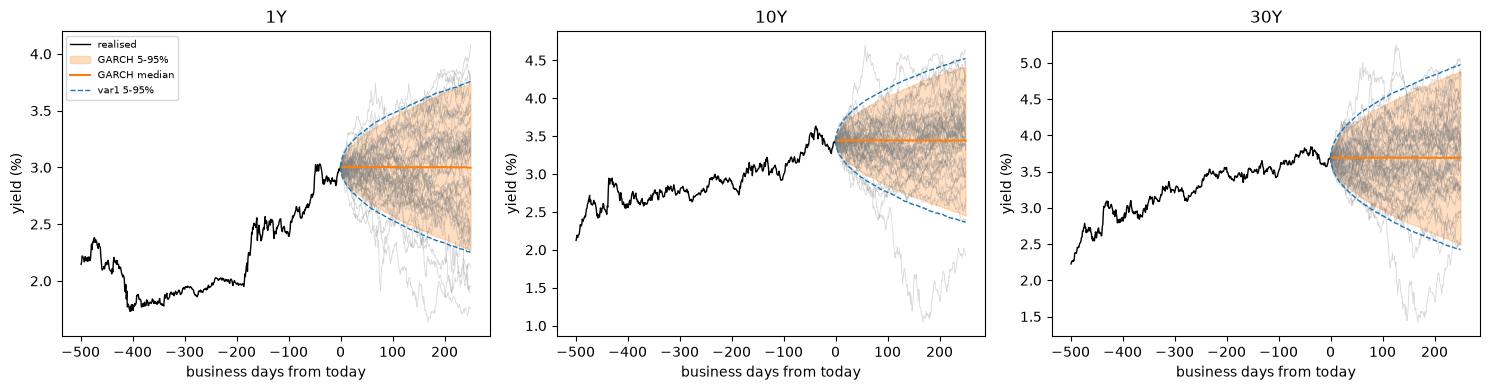

,5%,50%,95%,start,P(y<0)
1Y,2.278,2.998,3.744,3.004,0.000
2Y,2.157,3.118,4.104,3.125,0.001
5Y,2.197,3.185,4.174,3.188,0.000
10Y,2.450,3.439,4.415,3.442,0.000
20Y,2.656,3.729,4.793,3.729,0.000
30Y,2.500,3.693,4.883,3.692,0.000


In [6]:
cols = [0, len(levels.columns) // 2, -1]
HIST = 500
x = np.arange(cg.shape[1])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, j in zip(axes, cols):
    ax.plot(-np.arange(HIST, 0, -1) + 1, levels.iloc[-HIST:, j].values, color="black", lw=1, label="realised")
    ax.plot(x, cg[:50, :, j].T, color="grey", alpha=0.3, lw=0.6)
    lo, med, hi = np.percentile(cg[:, :, j], [5, 50, 95], axis=0)
    ax.fill_between(x, lo, hi, color="C1", alpha=0.25, label="GARCH 5-95%")
    ax.plot(x, med, color="C1", label="GARCH median")
    lo_b, _, hi_b = np.percentile(cb[:, :, j], [5, 50, 95], axis=0)
    ax.plot(x, lo_b, "C0--", lw=1, label="var1 5-95%"); ax.plot(x, hi_b, "C0--", lw=1)
    ax.set_title(f"{levels.columns[j]}"); ax.set_xlabel("business days from today"); ax.set_ylabel("yield (%)")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

q = pd.DataFrame(np.percentile(cg[:, -1], [5, 50, 95], axis=0).T, index=levels.columns, columns=["5%", "50%", "95%"])
q["start"] = y0
q["P(y<0)"] = (cg[:, -1] < 0).mean(axis=0)
q.round(3)